Praktikum 4 - Pra pengolahan data tidak terstruktur (citra).

Load Lenna.png (BGR OpenCV) -> RGB -> resize 128x128 -> grayscale.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("citra_lenna.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\praktikum-4


In [2]:
from pathlib import Path

import cv2
import matplotlib

import matplotlib.pyplot as plt
import numpy as np

BASE = Path(__file__).resolve().parent
IMG = BASE.parent / "data" / "Lenna.png"
OUT = BASE / "output"
OUT.mkdir(parents=True, exist_ok=True)

=== Citra asli ===
shape (H,W,C): (512, 512, 3) | dtype: uint8
piksel min/max/mean: 3 255 128.23
ukuran file: 462.7 KB


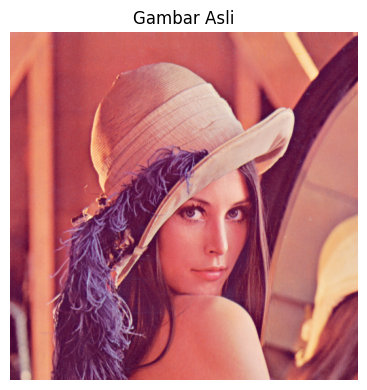

In [3]:
# ---------- Langkah 1: load gambar ----------
img = cv2.imread(str(IMG))
assert img is not None, f"gagal membaca {IMG}"
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("=== Citra asli ===")
print("shape (H,W,C):", img_rgb.shape, "| dtype:", img_rgb.dtype)
print("piksel min/max/mean:", img_rgb.min(), img_rgb.max(), round(float(img_rgb.mean()), 2))
print("ukuran file: %.1f KB" % (IMG.stat().st_size / 1024))

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img_rgb)
ax.set_title("Gambar Asli")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "01_asli.png", dpi=110)


=== Setelah resize ===
shape: (128, 128, 3) | jumlah piksel: 49152
mean sebelum/sesudah: 128.2284 / 128.2279


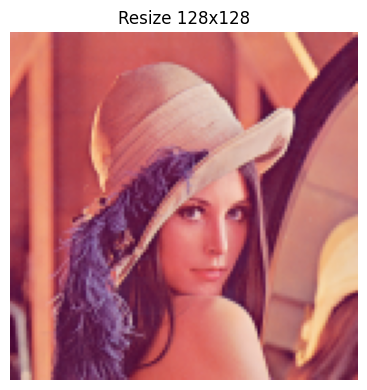

In [4]:
# ---------- Langkah 2: resize 128x128 ----------
img_resized = cv2.resize(img_rgb, (128, 128), interpolation=cv2.INTER_AREA)
print("\n=== Setelah resize ===")
print("shape:", img_resized.shape, "| jumlah piksel:", img_resized.size)
print("mean sebelum/sesudah: %.4f / %.4f" % (img_rgb.mean(), img_resized.mean()))

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img_resized)
ax.set_title("Resize 128x128")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "02_resize_128.png", dpi=110)


=== Grayscale ===
shape: (128, 128) | dtype: uint8
min/max/mean/std: 29 / 231 / 124.05 / 46.46


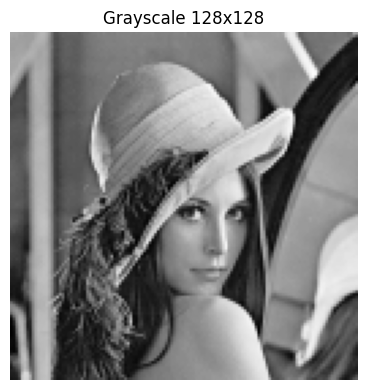

In [5]:
# ---------- Langkah 3: grayscale ----------
img_gray = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
print("\n=== Grayscale ===")
print("shape:", img_gray.shape, "| dtype:", img_gray.dtype)
print("min/max/mean/std: %d / %d / %.2f / %.2f"
      % (img_gray.min(), img_gray.max(), img_gray.mean(), img_gray.std()))

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img_gray, cmap="gray")
ax.set_title("Grayscale 128x128")
ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "03_grayscale.png", dpi=110)

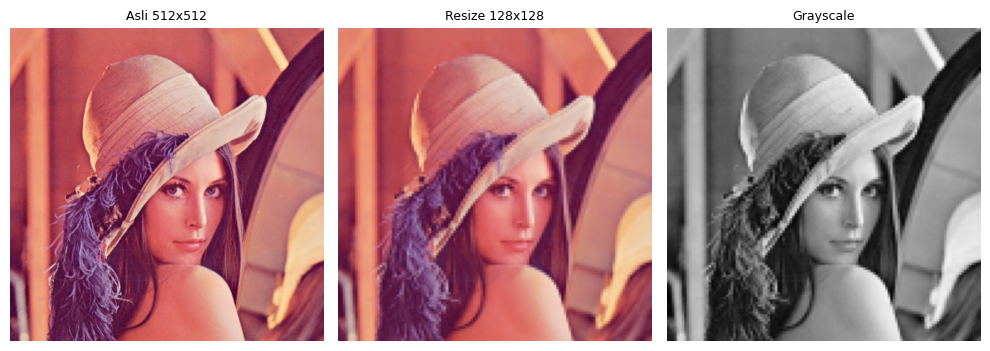

In [6]:
# ---------- Perbandingan ----------
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
for ax, im, title, cmap in [
    (axes[0], img_rgb, f"Asli {img_rgb.shape[1]}x{img_rgb.shape[0]}", None),
    (axes[1], img_resized, "Resize 128x128", None),
    (axes[2], img_gray, "Grayscale", "gray"),
]:
    ax.imshow(im, cmap=cmap)
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUT / "04_perbandingan.png", dpi=110)

In [7]:
# Simpan artefak hasil pra pengolahan (array siap ekstraksi fitur)
cv2.imwrite(str(OUT / "lenna_resized_rgb.png"), cv2.cvtColor(img_resized, cv2.COLOR_RGB2BGR))
cv2.imwrite(str(OUT / "lenna_gray_128.png"), img_gray)

True

In [8]:
# Bukti grayscale = rata-rata berbobot kanal (rumus BGR2GRAY OpenCV)
manual = cv2.cvtColor(img_resized, cv2.COLOR_RGB2GRAY)
print("\nselisih grayscale vs konversi ulang:", int(np.abs(img_gray.astype(int) - manual.astype(int)).max()))
print("Artefak tersimpan di:", OUT)


selisih grayscale vs konversi ulang: 0
Artefak tersimpan di: C:\code\pemmes26\js02-pemahaman-data-dan-pra-pengolahan-data\praktikum-4\output
